# Bài II – Mô hình dự báo khách hàng good / bad

**Mục tiêu:** dự báo xác suất một người nộp đơn vay trở thành khách hàng *bad* (`flag_bad = 1`), dựa trên demographic data (`de_`), phone data (`ph_`) và Facebook data (`fb_`).

1. **Khám phá dữ liệu**: dữ liệu trông thế nào, có vấn đề gì?
2. **Làm sạch và tạo biến**: biến dữ liệu thô thành tín hiệu có ý nghĩa
3. **Chia dữ liệu theo thời gian**: training set trên tháng 1–5, test set trên tháng 6–7
4. **Chọn biến bằng WOE / IV**
5. **Huấn luyện 2 mô hình**: Logistic Regression (scorecard) và Gradient Boosting
6. **Đánh giá và chọn mô hình**: AUC, PD dự báo có khớp thực tế không, mô hình dựa vào biến nào

## 0. Chuẩn bị dữ liệu

In [1]:
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

import warnings
# pandas báo cảnh báo vô hại khi chia nhóm có ô trống (NaN); kết quả không bị ảnh hưởng
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in cast")

import os
DATA_PATH = "data.csv" if os.path.exists("data.csv") else "../data.csv"
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Số dòng, số cột:", raw.shape)
print("Tỷ lệ bad: {:.2%}".format(raw["flag_bad"].mean()))

Số dòng, số cột: (41022, 22)
Tỷ lệ bad: 12.97%


In [2]:
raw.head()

,index,flag_bad,de_age,de_gender,de_date_joined,de_num_friends,de_monthly_salary,de_employment_type,de_employment_duration,de_accomodation_type,de_education,de_marital_status,de_children,ph_total_contacts,ph_other_device_info,ph_call_log_stats,ph_country_code,ph_app_list,fb_gender,fb_dob,fb_last_updated_date,fb_relation
0,0,0,26,1,08/04/2018 14:50,2535,3000000,1,51,4,2,2,0,66,"{""device_codename"": ""HM2014817"", ""brand"": ""Xia...","{""percent_incoming_nighttime"": 1.83, ""percent_...",id,"['com.google.android.music', 'com.facebook.orc...",male,11/23/1991,2017-12-21T04:38:00+0000,Married
1,1,0,22,1,02/01/2018 17:17,685,4000000,1,28,4,4,1,0,69,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.google.android.instantapps.supervisor', ...",male,01/20/1995,2017-11-25T17:23:09+0000,NaN
2,2,1,32,1,01/01/2018 16:39,1765,7000000,1,35,4,4,2,2,315,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 6.65, ""percent_...",id,"['com.tencent.ibg.joox', 'com.mrgames.larvaact...",male,10/13/1985,2017-12-23T18:05:57+0000,Married
3,3,0,31,2,04/01/2018 22:36,407,20000000,3,37,4,3,2,2,84,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.kfit.fave', 'app.bpjs.mobile', 'com.redd...",female,07/27/1986,2017-12-05T09:37:19+0000,Married
4,4,0,27,1,02/01/2018 18:12,3064,3000000,1,36,4,3,1,0,0,"{""device_codename"": ""1609"", ""brand"": ""vivo""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.lenovo.anyshare.gps', 'com.UCMobile.intl...",male,07/05/1990,2017-12-03T09:09:48+0000,In a relationship


## 1. Khám phá dữ liệu

### 1.1 Thiếu dữ liệu và kiểu cột

In [3]:
summary = pd.DataFrame({
    "datatype": raw.dtypes.astype(str),
    "% missing": (raw.isna().mean() * 100).round(1),
    "unique values": raw.nunique(),
})
summary

,datatype,% missing,unique values
index,int64,0.0,41022
flag_bad,int64,0.0,2
de_age,int64,0.0,50
de_gender,int64,0.0,2
de_date_joined,object,0.0,37120
de_num_friends,int64,0.0,4531
de_monthly_salary,int64,0.0,40
de_employment_type,int64,0.0,4
de_employment_duration,int64,0.0,52
de_accomodation_type,int64,0.0,1


- Phần lớn cột không thiếu dữ liệu. `fb_relation` thiếu 65%, `fb_dob` thiếu 24%. Thiếu ở đây có thể mang thông tin (người không khai báo), nên không bỏ dòng.
- `de_accomodation_type` chỉ có 1 giá trị, nên không giúp phân biệt ai.
- Một số cột là văn bản có cấu trúc (JSON, danh sách app), cần tách ra thành số ở bước 2.

In [4]:
print(raw["ph_other_device_info"].iloc[0])
print(raw["ph_call_log_stats"].iloc[0][:200], "...")
print(raw["ph_app_list"].iloc[0][:200], "...")
print("\nMã quốc gia:\n", raw["ph_country_code"].value_counts(dropna=False).head())

{"device_codename": "HM2014817", "brand": "Xiaomi"}
{"percent_incoming_nighttime": 1.83, "percent_outgoing_daytime": 28.44, "duration_incoming_daytime": 1195, "duration_outgoing_daytime": 1164, "percent_incoming_daytime": 3.67, "percent_other_calls": 2 ...
['com.google.android.music', 'com.facebook.orca', 'com.MantisGames.DriftandRallyFREE', 'com.apps.MyXL', 'com.google.android.instantapps.supervisor', 'com.classicpvcmob.bombermanclassic', 'com.miui.pla ...

Mã quốc gia:
 ph_country_code
id     40984
NaN       25
us         3
sg         3
my         2
Name: count, dtype: int64


### 1.2 Tỷ lệ bad theo tháng nộp đơn

$$\text{Tỷ lệ bad} = \frac{\text{số khách bad}}{\text{tổng số khách}}$$

,số hồ sơ,tỷ lệ bad
de_date_joined,,
2018-01,4472,0.148
2018-02,5564,0.148
2018-03,6144,0.132
2018-04,7006,0.107
2018-05,8589,0.122
2018-06,6322,0.139
2018-07,2925,0.118


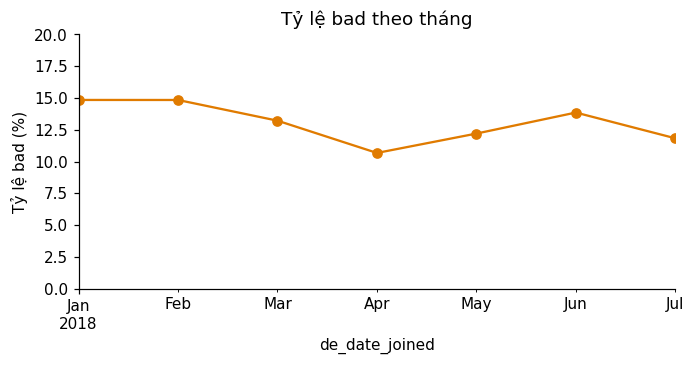

In [5]:
joined = pd.to_datetime(raw["de_date_joined"], format="%d/%m/%Y %H:%M")
by_month = raw.groupby(joined.dt.to_period("M"))["flag_bad"].agg(["size", "mean"])
by_month.columns = ["số hồ sơ", "tỷ lệ bad"]
display(by_month.round(3))

ax = by_month["tỷ lệ bad"].mul(100).plot(marker="o", figsize=(7, 3), color="#E07B00")
ax.set_ylim(0, 20); ax.set_ylabel("Tỷ lệ bad (%)"); ax.set_title("Tỷ lệ bad theo tháng")
plt.show()

Dữ liệu trải từ tháng 1 đến tháng 7/2018, tỷ lệ bad dao động 11–15%. Dữ liệu có thứ tự thời gian, nên khi kiểm tra mô hình cần dùng các tháng sau (xem bước 3).

Mã quốc gia gần như toàn bộ là `id`, nên đây nhiều khả năng là dữ liệu của một app cho vay ở Indonesia.

### 1.3 Tỷ lệ bad theo một vài biến khai báo

In [6]:
for col in ["de_education", "de_employment_type", "de_marital_status"]:
    t = raw.groupby(col)["flag_bad"].agg(["size", "mean"]).rename(columns={"size": "số hồ sơ", "mean": "tỷ lệ bad"})
    print("\n" + col)
    display(t.round(3))


de_education


,số hồ sơ,tỷ lệ bad
de_education,,
1,856,0.169
2,24589,0.146
3,5758,0.116
4,8258,0.099
5,1561,0.060



de_employment_type


,số hồ sơ,tỷ lệ bad
de_employment_type,,
1,29566,0.118
2,6621,0.157
3,4833,0.161
4,2,0.500



de_marital_status


,số hồ sơ,tỷ lệ bad
de_marital_status,,
1,20154,0.130
2,20020,0.126
3,500,0.196
4,348,0.256


In [7]:
# Tỷ lệ bad theo nhóm lương (chia theo phân vị; lương rất tập trung ở 3–4 triệu nên chỉ ra 4 nhóm)
salary = raw["de_monthly_salary"].replace(0, np.nan)              # lương = 0 coi là thiếu dữ liệu
nhom_luong = pd.qcut(salary, 5, duplicates="drop")                # cố chia 5 nhóm, gộp các mốc bị trùng
raw.groupby(nhom_luong, observed=True)["flag_bad"].agg(so_ho_so="size", ty_le_bad="mean").round(3)

,so_ho_so,ty_le_bad
de_monthly_salary,,
"(2999999.999, 4000000.0]",24585,0.127
"(4000000.0, 5000000.0]",6549,0.130
"(5000000.0, 6000000.0]",3164,0.146
"(6000000.0, 41000000.0]",6723,0.132


Học vấn càng cao thì tỷ lệ bad càng thấp. Một số nhóm rất nhỏ (`de_employment_type = 4` chỉ có 2 hồ sơ, hôn nhân 3–4 vài trăm hồ sơ), cần gộp lại để tỷ lệ ổn định.

Ngược lại với trực giác, lương gần như không phân biệt được good và bad: tỷ lệ bad ở các nhóm lương chỉ dao động từ khoảng 12,7% đến 14,6%, và không giảm dần khi lương tăng. Mục 4 sẽ đo điều này bằng IV.

## 2. Làm sạch và tạo biến

Máy không hiểu được một danh sách 40 tên app hay một chuỗi JSON. Ta tóm tắt chúng thành con số có ý nghĩa.

| Dữ liệu gốc | Biến mới | Lý do |
|---|---|---|
| `ph_app_list` | số app vay, số app ngân hàng, số app game, tổng số app | Người đang cài nhiều app vay có thể đang vay nhiều nơi |
| `ph_call_log_stats` | tổng cuộc gọi, % gọi đến/đi ngày/đêm, tổng thời lượng | Mức độ hoạt động xã hội |
| `ph_other_device_info` | hãng điện thoại | Có thể phản ánh thu nhập |
| `fb_dob`, `fb_gender` | tuổi FB lệch tuổi khai báo, giới tính FB có khớp không | Dấu hiệu khai gian |
| `fb_last_updated_date` | số ngày từ lần cập nhật FB đến lúc nộp đơn | Tài khoản còn hoạt động không |
| `de_date_joined` | tháng (để chia tập), giờ, ngày trong tuần | Hành vi nộp đơn |

**Công thức của một số biến mới:**

$$\text{lương (log)} = \ln(1 + \text{lương})$$

$$\text{lệch tuổi FB} = \left|\, \text{tuổi theo ngày sinh FB} - \text{tuổi khai báo} \,\right|$$

$$\text{số ngày từ lần cập nhật FB} = \text{ngày nộp đơn} - \text{ngày cập nhật FB}$$

$$\text{số app vay} = \text{số app có tên chứa từ khóa vay (loan, pinjam, kredit...)}$$

Chỉ dùng thông tin có tại lúc nộp đơn.

In [8]:
# Từ khóa nhận diện app (tiếng Anh + tiếng Indonesia)
LOAN_KEYWORDS = ("pinjam", "kredit", "loan", "cash", "dana", "uang", "rupiah", "credit",
                 "akulaku", "silvrr", "tunaiku", "modal", "kta", "paylater")
BANK_KEYWORDS = ("bca", "bni", "mandiri", "bri", "cimb", "danamon", "permata", "btn", "jenius")
GAME_KEYWORDS = ("game", "legends", "pubg", "freefire", "dts.freefire", "clash")
# Kredivo có trên ~98% máy, nhiều khả năng là chính app cho vay, nên không đếm
IGNORE_APPS = {"com.finaccel.android"}

apps = raw["ph_app_list"].apply(ast.literal_eval)
share = pd.Series([a for l in apps for a in set(l)]).value_counts() / len(raw)
print("App phổ biến nhất:\n", share.head(5).round(3))

App phổ biến nhất:
 com.finaccel.android                         0.978
com.whatsapp                                 0.946
com.instagram.android                        0.744
com.google.android.instantapps.supervisor    0.726
com.grabtaxi.passenger                       0.614
Name: count, dtype: float64


In [9]:
def count_keywords(app_list, keywords):
    return sum(1 for a in app_list if a not in IGNORE_APPS and any(k in a.lower() for k in keywords))

def relation_group(x):
    if pd.isna(x):
        return "Not declared"
    x = str(x)
    if x.startswith("Married"):
        return "Married"
    if x.startswith("Single"):
        return "Single"
    if x.startswith("In a relationship") or x.startswith("Engaged"):
        return "In a relationship / engaged"
    return "Other"

d = raw
df = pd.DataFrame({"flag_bad": d["flag_bad"]})

# Thời điểm nộp đơn
df["month"] = joined.dt.to_period("M").astype(str)
df["apply_hour"] = joined.dt.hour
df["apply_weekday"] = np.where(joined.dt.dayofweek >= 5, "Weekend", "Weekday")

# Nhân khẩu học
df["age"] = d["de_age"]
df["gender"] = d["de_gender"].map({1: "Male", 2: "Female"})
df["num_friends"] = d["de_num_friends"].replace(-1, np.nan)               # -1 = không có dữ liệu
df["log_salary"] = np.log1p(d["de_monthly_salary"].replace(0, np.nan))    # lương lệch phải → log
df["employment_type"] = d["de_employment_type"].map(
    {1: "Full-time", 2: "Part-time", 3: "Business owner", 4: "Full-time"})   # 4: không có trong đề, 2 hồ sơ
df["employment_duration"] = d["de_employment_duration"]
df["education"] = d["de_education"]
df["marital_status"] = d["de_marital_status"].map(
    {1: "Single", 2: "Married", 3: "Divorced / widowed", 4: "Divorced / widowed"})
df["children"] = d["de_children"]

# Điện thoại
df["total_contacts"] = d["ph_total_contacts"]
df["contacts_zero"] = np.where(d["ph_total_contacts"] == 0, "Yes", "No")
brand = d["ph_other_device_info"].apply(lambda s: json.loads(s).get("brand", "unknown")).str.lower()
df["device_brand"] = brand.where(brand.isin(brand.value_counts().index[:8]), "other")

calls = pd.DataFrame(d["ph_call_log_stats"].apply(lambda s: json.loads(s) if isinstance(s, str) else {}).tolist())
df["call_total"] = calls["total_calls"]
df["call_pct_in_day"] = calls["percent_incoming_daytime"]
df["call_pct_in_night"] = calls["percent_incoming_nighttime"]
df["call_pct_out_day"] = calls["percent_outgoing_daytime"]
df["call_pct_out_night"] = calls["percent_outgoing_nighttime"]
df["call_pct_other"] = calls["percent_other_calls"]
dur_cols = [c for c in calls.columns if c.startswith("duration")]
df["call_dur_total_log"] = np.log1p(calls[dur_cols].sum(axis=1, min_count=1))

df["n_apps"] = apps.str.len()
df["n_loan_apps"] = apps.apply(lambda a: count_keywords(a, LOAN_KEYWORDS))
df["n_bank_apps"] = apps.apply(lambda a: count_keywords(a, BANK_KEYWORDS))
df["n_game_apps"] = apps.apply(lambda a: count_keywords(a, GAME_KEYWORDS))

# Facebook: kiểm tra tính nhất quán với thông tin khai báo
df["has_fb"] = np.where(d["fb_gender"].notna() | d["fb_last_updated_date"].notna(), "Yes", "No")
fb_gender = d["fb_gender"].map({"male": 1, "female": 2})
df["fb_gender_mismatch"] = np.select([fb_gender.isna(), fb_gender != d["de_gender"]], ["No FB", "Mismatch"], "Match")
fb_age = (joined - pd.to_datetime(d["fb_dob"], format="%m/%d/%Y", errors="coerce")).dt.days / 365.25
df["fb_age_gap"] = (fb_age - d["de_age"]).abs()
fb_upd = pd.to_datetime(d["fb_last_updated_date"], utc=True, errors="coerce").dt.tz_localize(None)
df["fb_days_since_update"] = (joined - fb_upd).dt.days.clip(lower=0)   # 0,2% cập nhật sau ngày nộp đơn → đặt về 0
df["fb_relation_group"] = d["fb_relation"].apply(relation_group)

NUMERIC = ["age", "num_friends", "log_salary", "employment_duration", "children", "education",
           "apply_hour", "total_contacts", "n_apps", "n_loan_apps", "n_bank_apps", "n_game_apps",
           "call_total", "call_pct_in_day", "call_pct_in_night", "call_pct_out_day", "call_pct_out_night",
           "call_pct_other", "call_dur_total_log", "fb_age_gap", "fb_days_since_update"]
CATEGORICAL = ["gender", "employment_type", "marital_status", "apply_weekday", "device_brand",
               "fb_relation_group", "fb_gender_mismatch", "has_fb", "contacts_zero"]
print("Số biến:", len(NUMERIC) + len(CATEGORICAL))
df.head()

.venv/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


Số biến: 30


,flag_bad,month,apply_hour,apply_weekday,age,gender,num_friends,log_salary,employment_type,employment_duration,education,marital_status,children,total_contacts,contacts_zero,device_brand,call_total,call_pct_in_day,call_pct_in_night,call_pct_out_day,call_pct_out_night,call_pct_other,call_dur_total_log,n_apps,n_loan_apps,n_bank_apps,n_game_apps,has_fb,fb_gender_mismatch,fb_age_gap,fb_days_since_update,fb_relation_group
0,0,2018-04,14,Weekend,26,Male,2535.0,14.914123,Full-time,51,2,Married,0,66,No,xiaomi,109.0,3.67,1.83,28.44,63.30,2.75,10.714662,54,0,0,4,Yes,Match,0.373717,108.0,Married
1,0,2018-01,17,Weekday,22,Male,685.0,15.201805,Full-time,28,4,Single,0,69,No,oppo,2.0,0.00,0.00,100.00,0.00,0.00,0.000000,51,0,0,1,Yes,Match,0.951403,37.0,Not declared
2,1,2018-01,16,Weekday,32,Male,1765.0,15.761421,Full-time,35,4,Married,2,315,No,oppo,376.0,13.56,6.65,41.76,24.73,13.30,9.646011,47,1,1,3,Yes,Match,0.219028,8.0,Married
3,0,2018-01,22,Weekday,31,Female,407.0,16.811243,Business owner,37,3,Married,2,84,No,oppo,0.0,0.00,0.00,0.00,0.00,0.00,0.000000,42,3,1,0,Yes,Match,0.441478,30.0,Married
4,0,2018-01,18,Weekday,27,Male,3064.0,14.914123,Full-time,36,3,Single,0,0,Yes,vivo,15.0,0.00,0.00,46.67,53.33,0.00,4.595120,17,0,0,0,Yes,Match,0.496235,30.0,In a relationship / engaged


- Bỏ `de_accomodation_type` và `ph_country_code`: gần như chỉ có một giá trị.
- `de_num_friends = -1` và lương = 0 được coi là thiếu dữ liệu.
- Gộp các nhóm quá nhỏ: hôn nhân 3–4 (vài trăm hồ sơ) gộp thành "Divorced / widowed". Mã công việc 4 không có trong mô tả của đề và chỉ có 2 hồ sơ, nên không xác định được ý nghĩa; gộp vào nhóm đông nhất (Full-time, 72% hồ sơ) thay vì để thành nhóm riêng.
- Không đếm app Kredivo khi đếm app vay.

## 3. Chia dữ liệu: training, validation và test set

| Tập | Dữ liệu | Dùng để |
|---|---|---|
| **Training set** | 75% hồ sơ tháng 1–5 | Huấn luyện mô hình |
| **Validation set** | 25% hồ sơ tháng 1–5 | So sánh, phát hiện overfitting trong lúc xây mô hình |
| **Test set (out-of-time)** | Toàn bộ hồ sơ tháng 6–7 | Đánh giá cuối cùng trên dữ liệu mô hình chưa từng thấy |

**Vì sao test set là 2 tháng cuối?** Khi dùng thật, mô hình luôn chấm cho khách hàng *trong tương lai*, nên test trên các tháng sau mô phỏng đúng tình huống đó. Basel khuyến nghị kiểm tra khả năng phân biệt trên dữ liệu không dùng lúc xây mô hình, để tránh đánh giá quá cao do overfitting [3, tr. 36]. Chia theo thời gian (out-of-time) còn chặt chẽ hơn: dữ liệu kiểm tra vừa độc lập, vừa thuộc giai đoạn sau. Mục 6.4 so sánh chi tiết với cách chia ngẫu nhiên.

$$\underbrace{\text{Training (75\%)} + \text{Validation (25\%)}}_{\text{tháng 1–5}} \qquad\qquad \underbrace{\text{Test}}_{\text{tháng 6–7}}$$

In [10]:
OOT_MONTHS = ["2018-06", "2018-07"]
is_oot = df["month"].isin(OOT_MONTHS)
dev, test = df[~is_oot], df[is_oot]
train, valid = train_test_split(dev, test_size=0.25, stratify=dev["flag_bad"], random_state=SEED)
sets = {"Train": train, "Validation": valid, "Test OOT": test}

pd.DataFrame({k: {"số hồ sơ": len(v), "tỷ lệ bad": "{:.1%}".format(v["flag_bad"].mean())} for k, v in sets.items()}).T

,số hồ sơ,tỷ lệ bad
Train,23831,12.9%
Validation,7944,12.9%
Test OOT,9247,13.2%


Test set chỉ dùng một lần ở cuối, không dùng để chọn biến hay chỉnh tham số.

## 4. Chọn biến bằng WOE và IV

**Biến và nhóm khác nhau thế nào?**
- **Biến** là một cột thông tin của khách, ví dụ "số app vay trong máy".
- **Nhóm** là các khoảng giá trị mà một biến được chia ra. Ví dụ biến "số app vay" được chia thành 4 nhóm: 0 app, 1 app, 2 app, từ 3 app trở lên.

Ý tưởng: chia mỗi biến thành vài nhóm, xem tỷ lệ bad của từng nhóm. Các nhóm càng khác nhau thì biến càng có ích. **WOE** tính cho từng **nhóm**, còn **IV** cộng các nhóm lại thành một con số cho cả **biến**.

Với mỗi biến, gọi $i$ là nhóm thứ $i$ của biến đó:

$$\%\text{good}_i = \frac{\text{số good trong nhóm } i}{\text{tổng số good}} \qquad \%\text{bad}_i = \frac{\text{số bad trong nhóm } i}{\text{tổng số bad}}$$

**WOE** (Weight of Evidence), "điểm rủi ro" của từng nhóm. Dương là an toàn hơn trung bình, âm là rủi ro hơn:

$$\text{WOE}_i = \ln\left(\frac{\%\text{good}_i}{\%\text{bad}_i}\right)$$

**IV** (Information Value), sức dự báo của cả biến.

$$\text{IV} = \sum_i \left(\%\text{good}_i - \%\text{bad}_i\right) \times \text{WOE}_i$$

**Ví dụ: biến "số app vay"** (training set: 20.758 good, 3.073 bad)

| Nhóm | %good | %bad | WOE | (%good − %bad) × WOE |
|---|---|---|---|---|
| 0 app | 42,2% | 26,9% | +0,45 | 0,069 |
| 1 app | 34,5% | 28,6% | +0,19 | 0,011 |
| 2 app | 12,0% | 13,3% | −0,11 | 0,001 |
| từ 3 app | 11,4% | 31,2% | −1,01 | 0,201 |
| **IV của cả biến** | | | | **≈ 0,28** |

- Mỗi nhóm có một WOE: nhóm "0 app" an toàn (+0,45), nhóm "từ 3 app" rủi ro (−1,01).
- Cộng 4 nhóm lại ra **IV = 0,28** cho cả biến: biến mạnh nhất trong bài. Nhóm "từ 3 app" đóng góp nhiều nhất vì vừa lệch nhiều vừa đông người.
- So sánh với biến lương (đã thấy ở mục 1.3): tỷ lệ bad ở các nhóm lương gần như bằng nhau, nên %good ≈ %bad ở mọi nhóm, WOE ≈ 0 và **IV chỉ 0,002**. Lương gần như không giúp phân biệt good và bad, nên bị loại ở quy tắc 1 (mục 4.3).

Các nhóm và WOE chỉ được học trên training set, rồi áp nguyên cho validation và test.

WOE và IV là công cụ chuẩn khi xây scorecard tín dụng [1][2].

In [11]:
MISSING = "Missing"

def numeric_edges(x, max_bins=6, min_share=0.05):
    # Chia theo phân vị, rồi gộp nhóm nhỏ (< 5% hồ sơ) vào nhóm bên cạnh
    qs = np.unique(np.nanquantile(x, np.linspace(0, 1, max_bins + 1)))
    edges = [-np.inf] + list(qs[:-1]) + [np.inf]
    while len(edges) > 3:
        counts = pd.cut(x, edges, include_lowest=True).value_counts(sort=False, normalize=True).to_numpy()
        i = int(np.argmin(counts))
        if counts[i] >= min_share:
            break
        del edges[i if i > 0 else 1]
    return edges

def to_bins(x, spec):
    if spec["kind"] == "numeric":
        lab = pd.cut(x, spec["edges"], include_lowest=True).astype(str)
        return lab.where(x.notna(), MISSING)
    lab = x.astype(object).where(x.notna(), MISSING).astype(str)
    return lab.where(lab.isin(spec["keep"]), "Other")

def woe_table(lab, y):
    t = pd.DataFrame({"bin": lab, "y": y}).groupby("bin")["y"].agg(n="size", bad="sum")
    t["good"] = t["n"] - t["bad"]
    t["pct_good"] = (t["good"] + 0.5) / (t["good"].sum() + 0.5)   # +0,5 tránh chia cho 0
    t["pct_bad"] = (t["bad"] + 0.5) / (t["bad"].sum() + 0.5)
    t["bad_rate"] = t["bad"] / t["n"]
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv_part"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    return t

def fit_binning(x, y, kind):
    if kind == "numeric":
        spec = {"kind": kind, "edges": numeric_edges(x)}
    else:
        share = x.astype(object).where(x.notna(), MISSING).value_counts(normalize=True)
        spec = {"kind": kind, "keep": set(share[share >= 0.05].index.astype(str))}
    t = woe_table(to_bins(x, spec), y)
    if kind == "numeric":   # sắp nhóm theo thứ tự giá trị
        order = [str(iv) for iv in pd.IntervalIndex.from_breaks(spec["edges"], closed="right")]
        t = t.reindex([o for o in order if o in t.index] + [i for i in t.index if i not in order])
    spec.update(table=t, woe=t["woe"].to_dict(), iv=float(t["iv_part"].sum()))
    return spec

def woe_transform(frame, specs, cols):
    return pd.DataFrame({c: to_bins(frame[c], specs[c]).map(specs[c]["woe"]).fillna(0.0) for c in cols}, index=frame.index)

specs = {c: fit_binning(train[c], train["flag_bad"], "numeric") for c in NUMERIC}
specs.update({c: fit_binning(train[c], train["flag_bad"], "categorical") for c in CATEGORICAL})

### 4.1 Tỷ lệ bad theo nhóm của 3 biến có ảnh hưởng 

WOE và IV được tính cho cả 30 biến (xem bảng IV ở mục 4.3). Ở đây vẽ 3 biến có ảnh hưởng:
- **Số app vay:** biến mạnh nhất (IV 0,28).
- **Tổng số app:** đi theo chiều ngược lại (ít app thì rủi ro hơn), cho thấy không phải biến nào cũng "càng nhiều càng xấu".
- **Học vấn:** biến nhân khẩu học duy nhất có sức dự báo.

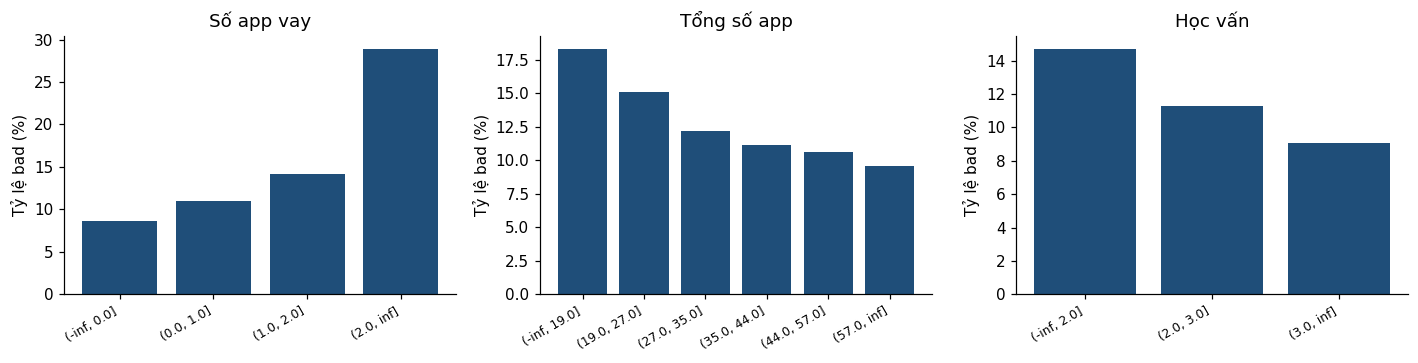

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c, name in zip(axes, ["n_loan_apps", "n_apps", "education"], ["Số app vay", "Tổng số app", "Học vấn"]):
    t = specs[c]["table"]
    ax.bar(range(len(t)), t["bad_rate"] * 100, color="#1F4E79")
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(name); ax.set_ylabel("Tỷ lệ bad (%)")
plt.tight_layout(); plt.show()

Người không có app vay có tỷ lệ bad khoảng 9%, còn người có từ 3 app vay trở lên khoảng 29%, cao gấp hơn 3 lần. Điều này có thể giải thích là người vay nhiều nơi thì đang có khả năng tài chính yếu hơn, và cũng phải trả nhiều khoản vay khác nhau hơn nên dễ mất khả năng trả nợ, tỉ lệ bad cũng cao hơn. Ít app cũng rủi ro hơn, vì có thể là máy mới và ứng dụng vay được cài vội để vay gấp. Học vấn cao thì rủi ro thấp hơn.

### 4.2 Thay giá trị gốc bằng WOE

Sau khi có bảng WOE của từng biến, **mỗi khách được thay giá trị gốc bằng WOE của nhóm mà họ rơi vào**, làm với từng biến. Ví dụ 5 khách trong training set:

In [13]:
example_cols = sorted(NUMERIC + CATEGORICAL, key=lambda c: specs[c]["iv"], reverse=True) 
pd.set_option("display.max_columns", 100)    
sample = train.sample(5, random_state=1)
x_example = woe_transform(sample, specs, example_cols)

show = pd.DataFrame(index=sample.index)
for c in example_cols:
    show[(c, "giá trị gốc")] = sample[c]
    show[(c, "nhóm")] = to_bins(sample[c], specs[c])
    show[(c, "WOE")] = x_example[c].round(2)
show.columns = pd.MultiIndex.from_tuples(show.columns)
show

n_loan_apps                    n_bank_apps                         n_apps                       education                    call_pct_in_day  \
      giá trị gốc         nhóm   WOE giá trị gốc         nhóm   WOE giá trị gốc          nhóm   WOE giá trị gốc         nhóm   WOE     giá trị gốc   
32981           0  (-inf, 0.0]  0.45           0  (-inf, 0.0] -0.25          12  (-inf, 19.0] -0.42           4   (3.0, inf]  0.39           35.04   
14482           0  (-inf, 0.0]  0.45           1   (0.0, 1.0]  0.16          41  (35.0, 44.0]  0.17           2  (-inf, 2.0] -0.16           19.18   
27115           0  (-inf, 0.0]  0.45           2   (1.0, 2.0]  0.42          39  (35.0, 44.0]  0.17           4   (3.0, inf]  0.39            9.82   
28444           2   (1.0, 2.0] -0.11           1   (0.0, 1.0]  0.16          19  (-inf, 19.0] -0.42           2  (-inf, 2.0] -0.16            0.00   
2372            0  (-inf, 0.0]  0.45           1   (0.0, 1.0]  0.16          44  (35.0, 44.0]  0.17           4   (3.0, inf]  0.39           31.40   

                             call_pct_other                         call_total                        fb_age_gap                       employment_duration  \
                  nhóm   WOE    giá trị gốc             nhóm   WOE giá trị gốc            nhóm   WOE giá trị gốc            nhóm   WOE         giá trị gốc   
32981    (32.123, inf]  0.24          27.68    (20.0, 28.38]  0.10       448.0    (185.0, inf] -0.30         NaN         Missing  0.20                  51   
14482  (16.775, 22.97]  0.08          72.60    (41.733, inf] -0.31        73.0   (65.0, 106.0]  0.07    0.947296  (0.772, 0.996] -0.11                  36   
27115    (4.76, 11.33] -0.22          21.43    (20.0, 28.38]  0.10       112.0  (106.0, 185.0]  0.01         NaN         Missing  0.20                  48   
28444     (-inf, 4.76] -0.30           0.00      (-inf, 0.0] -0.17         3.0    (-inf, 14.0] -0.18         NaN         Missing  0.20                  12   
2372   (22.97, 32.123]  0.24          29.75  (28.38, 41.733] -0.09       121.0  (106.0, 185.0]  0.01    0.093087   (-inf, 0.194]  0.17                  12   

                          employment_type                  call_dur_total_log                       fb_days_since_update                      \
               nhóm   WOE     giá trị gốc       nhóm   WOE        giá trị gốc            nhóm   WOE          giá trị gốc          nhóm   WOE   
32981   (36.0, inf]  0.20       Full-time  Full-time  0.11          10.010187    (9.187, inf]  0.06                 13.0   (8.0, 18.0] -0.10   
14482  (24.0, 36.0] -0.20       Full-time  Full-time  0.11           7.118826  (6.825, 7.663]  0.13                 19.0  (18.0, 33.0]  0.04   
27115   (36.0, inf]  0.20       Full-time  Full-time  0.11           7.629976  (6.825, 7.663]  0.13                151.0  (130.0, inf]  0.14   
28444  (-inf, 13.0]  0.02       Full-time  Full-time  0.11           4.770685    (0.0, 5.352] -0.21                 16.0   (8.0, 18.0] -0.10   
2372   (-inf, 13.0]  0.02       Full-time  Full-time  0.11           8.902864  (8.375, 9.187]  0.07                 16.0   (8.0, 18.0] -0.10   

      call_pct_out_night                      num_friends                          call_pct_out_day                       call_pct_in_night                \
             giá trị gốc           nhóm   WOE giá trị gốc               nhóm   WOE      giá trị gốc            nhóm   WOE       giá trị gốc          nhóm   
32981               8.04   (5.15, 9.43]  0.17      1269.0  (867.0, 1309.333]  0.06            27.46  (24.56, 34.35] -0.03              1.79  (1.35, 3.17]   
14482               0.00    (-inf, 0.0] -0.08        71.0      (-inf, 319.0] -0.25             8.22    (0.0, 11.76] -0.05              0.00   (-inf, 0.0]   
27115              11.61  (9.43, 14.53]  0.08      3857.0      (2198.0, inf] -0.01            55.36  (44.0, 55.642]  0.13              1.79  (1.35, 3.17]   
28444              33.33   (23.08, inf] -0.20       54

**Cách đọc:** khách có 0 app vay rơi vào nhóm `(-inf, 0.0]`, nên nhận WOE +0,45 (nhóm an toàn). Cùng khách đó có thể rơi vào nhóm rủi ro của biến khác, ví dụ ít app nói chung (WOE âm).

Sau bước này, **mỗi biến trở thành một cột số WOE**, mỗi khách một số. Bảng số này là:
- dữ liệu dùng để tính **tương quan** ở quy tắc 2 (tương quan giữa hai cột WOE),
- dữ liệu đưa vào **Logistic Regression** ở bước 5.

### 4.3 Chọn biến

**Quy tắc 1: bỏ biến có IV < 0,02.** Cách đọc IV theo Siddiqi (2006) [1], trích lại trong Delamaire (2012, tr. 152) [2]: < 0,02 không có ích, 0,02–0,1 yếu, 0,1–0,3 trung bình, > 0,3 mạnh. Ngưỡng 0,5 là quy ước kinh nghiệm thường dùng thêm:

| IV | Ý nghĩa |
|---|---|
| < 0,02 | Không có ích |
| 0,02 – 0,1 | Yếu |
| 0,1 – 0,3 | Trung bình |
| 0,3 – 0,5 | Mạnh |
| > 0,5 | Mạnh đáng ngờ: cần kiểm tra lại (quy ước kinh nghiệm) |

IV > 0,5 đáng ngờ vì hiếm có biến nào lúc nộp đơn một mình tách good/bad rõ đến vậy. Hai nguyên nhân thường gặp:
- **Rò rỉ dữ liệu (data leakage):** biến chứa thông tin chỉ có *sau* khi biết kết quả [9], ví dụ số ngày quá hạn. Trong bài, 0,2% hồ sơ có ngày cập nhật Facebook sau ngày nộp đơn, nên đã được đặt về 0 (bước 2).
- **Nhóm quá nhỏ:** WOE của nhóm có vài hồ sơ rất cực đoan do tình cờ, làm IV bị thổi phồng trên train nhưng không lặp lại trên test (overfitting). Bài gộp các nhóm dưới 5% hồ sơ để tránh việc này.

**Quy tắc 2: bỏ biến tương quan > 0,6 với một biến đã chọn có IV cao hơn.** Hai biến tương quan cao gần như nói cùng một điều, ví dụ "số danh bạ" và "danh bạ có bằng 0 không". Giữ cả hai không thêm thông tin, mà còn làm mô hình khó xác định biến nào quan trọng, nên hệ số có thể dao động, thậm chí đổi dấu (hiện tượng đa cộng tuyến [4]). Vì vậy chỉ giữ biến có IV cao hơn.

**Quy tắc 3: bỏ biến có hệ số logistic ngược dấu.** Trong Logistic Regression (mục 5.1), mỗi biến có một hệ số cho biết biến đó đẩy PD lên hay kéo PD xuống. Vì WOE cao nghĩa là nhóm an toàn, hệ số đúng phải **âm**: nhóm càng an toàn thì PD càng thấp. Nếu hệ số ra dương, mô hình đang chấm nhóm an toàn thành rủi ro hơn, trái với dữ liệu và không giải thích được cho khách, nên biến đó bị loại. Siddiqi (2006) yêu cầu dấu của biến phải đúng logic nghiệp vụ, trích lại trong Delamaire (2012, tr. 152) [1][2].

In [14]:
x_woe = {k: woe_transform(v, specs, NUMERIC + CATEGORICAL) for k, v in sets.items()}
iv = pd.Series({c: s["iv"] for c, s in specs.items()}).sort_values(ascending=False)
corr = x_woe["Train"].corr().abs()

decision, selected = {}, []
for c in iv.index:
    if iv[c] < 0.02:
        decision[c] = "Loại: IV < 0,02"
    elif any(corr.loc[c, k] > 0.6 for k in selected):
        decision[c] = "Loại: tương quan cao"
    else:
        selected.append(c); decision[c] = "Giữ"

iv_log = pd.DataFrame({"IV": iv.round(4), "Quyết định": pd.Series(decision)})
iv_log

,IV,Quyết định
n_loan_apps,0.2827,Giữ
n_bank_apps,0.0788,Giữ
n_apps,0.0692,Giữ
education,0.0507,Giữ
call_pct_in_day,0.0505,Giữ
call_pct_other,0.0400,Giữ
call_total,0.0398,Giữ
fb_age_gap,0.0391,Giữ
employment_duration,0.0378,Giữ
employment_type,0.0288,Giữ


In [15]:
# Quy tắc 2: các cặp biến có tương quan WOE > 0,6 trên training set
corr_all = x_woe["Train"].corr().abs()
pairs = [(a, b, corr_all.loc[a, b]) for k, a in enumerate(corr_all.index)
         for b in corr_all.index[k + 1:] if corr_all.loc[a, b] > 0.6]
sel_corr = corr_all.loc[selected, selected].where(~np.eye(len(selected), dtype=bool))
print("Tương quan cao nhất giữa các biến đã qua quy tắc 1:", round(sel_corr.max().max(), 2))
pd.DataFrame([{"Biến 1": a, "Biến 2": b, "Tương quan": round(v, 2),
               "Quyết định biến 1": decision[a], "Quyết định biến 2": decision[b]} for a, b, v in pairs])

Tương quan cao nhất giữa các biến đã qua quy tắc 1: 0.56


,Biến 1,Biến 2,Tương quan,Quyết định biến 1,Quyết định biến 2
0,total_contacts,contacts_zero,0.76,"Loại: IV < 0,02","Loại: IV < 0,02"
1,call_pct_in_night,call_pct_out_day,0.64,"Loại: IV < 0,02","Loại: IV < 0,02"
2,call_pct_in_night,call_dur_total_log,0.68,"Loại: IV < 0,02",Giữ
3,call_pct_out_day,call_pct_other,0.65,"Loại: IV < 0,02",Giữ
4,call_pct_out_day,call_dur_total_log,0.66,"Loại: IV < 0,02",Giữ


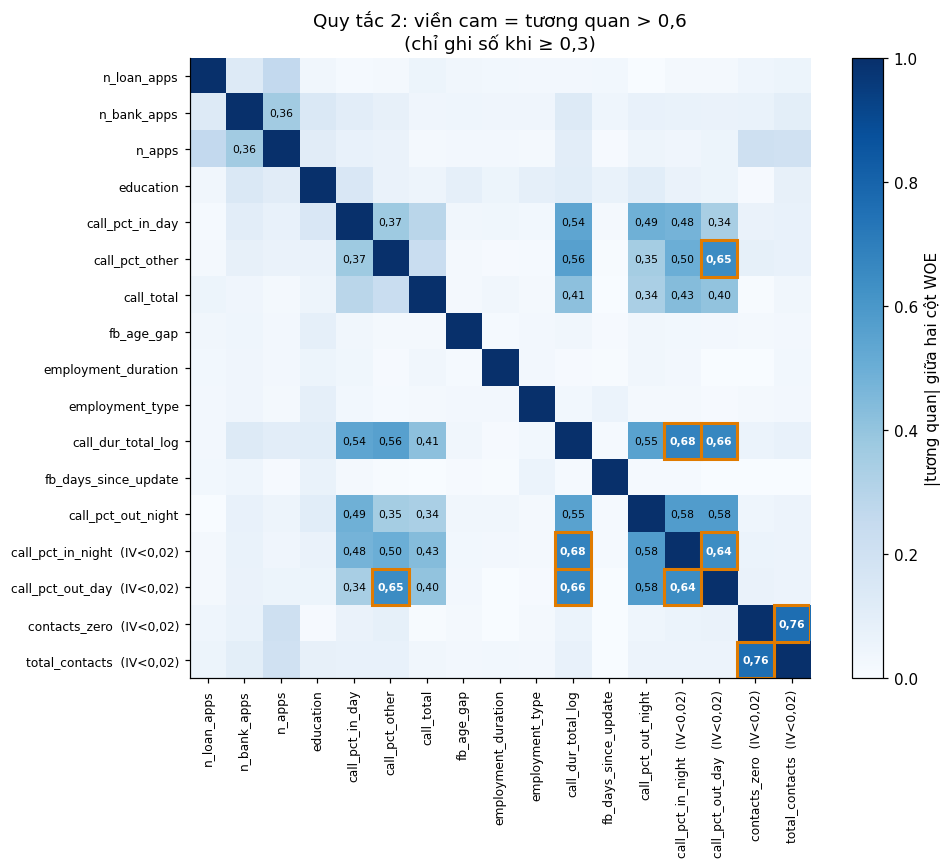

In [16]:
# Correlation giữa các cột WOE (biến qua quy tắc 1 + các biến nằm trong cặp > 0,6)
show_vars = [c for c in iv.index if iv[c] >= 0.02] + sorted({v for a, b, _ in pairs for v in (a, b) if iv[v] < 0.02})
m = corr_all.loc[show_vars, show_vars]
names = [f"{v}  (IV<0,02)" if iv[v] < 0.02 else v for v in show_vars]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
for r_ in range(len(names)):
    for c_ in range(len(names)):
        v = m.iloc[r_, c_]
        if r_ != c_ and v >= 0.3:
            ax.text(c_, r_, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 else "black", fontweight="bold" if v > 0.6 else "normal")
        if r_ != c_ and v > 0.6:
            ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, fill=False, edgecolor="#E07B00", lw=2))
plt.colorbar(im, ax=ax, fraction=0.04, label="|tương quan| giữa hai cột WOE")
ax.set_title("Quy tắc 2: viền cam = tương quan > 0,6\n(chỉ ghi số khi ≥ 0,3)")
plt.tight_layout(); plt.show()

Các cặp tương quan trên 0,6 đều có ít nhất một biến đã bị loại ở quy tắc 1 (IV < 0,02). Trong các biến còn lại, tương quan cao nhất chỉ khoảng 0,56, nên **quy tắc 2 không phải loại thêm biến nào**. Quy tắc này vẫn giữ lại như một lớp bảo vệ.

Ví dụ, với tổng thời lượng gọi: phần lớn thông tin của nó (người hay gọi điện là người có đời sống xã hội ổn định) đã được các biến cuộc gọi khác nói rồi. Phần riêng còn lại rất nhỏ, gần như là nhiễu, và tình cờ nghiêng về hướng ngược lại. Kết quả là hệ số ra dương.

## 5. Hai mô hình

**Logistic Regression:** mỗi biến được nhân với một hệ số rồi cộng lại thành một tổng *z*. Tổng này được đưa qua hàm logistic để luôn ra một số từ 0 đến 1:

$$PD = \frac{1}{1 + e^{-z}}$$

Hệ số được chọn sao cho PD dự báo khớp nhất với dữ liệu good/bad đã biết [4, chương 4]. Mô hình chỉ là một phép cộng nên có thể đổi thẳng mỗi nhóm của mỗi biến thành scorecard [1].

**Gradient Boosting:** Cây đầu tiên đưa ra dự đoán. Cây tiếp theo học phần sai của cây trước đó, và quá trình này được lặp lại đến hết số lượng cây. Mỗi cây chỉ đóng góp một phần nhỏ (learning rate 0,05) để mô hình học từ từ và tránh overfitting [4, mục 8.2.3]. "Gradient" nghĩa là mỗi cây đi theo hướng làm sai số giảm nhanh nhất (steepest descent) [5, mục 10.10][6]. Bài dùng `HistGradientBoostingClassifier` của scikit-learn: chia giá trị mỗi biến thành các khoảng (histogram) để chạy nhanh, theo ý tưởng của LightGBM [7].


| | Logistic Regression trên WOE (scorecard) | Gradient Boosting |
|---|---|---|
| Ưu điểm | Dễ giải thích, chuẩn ngành ngân hàng, ổn định | Bắt được quan hệ phi tuyến và tương tác giữa biến |
| Nhược điểm | Bỏ lỡ tương tác giữa biến | Khó giải thích hơn, dễ overfitting |

Một nghiên cứu so sánh nhiều thuật toán trên 8 bộ dữ liệu tín dụng cho thấy nhiều thuật toán, nhất là các mô hình tổ hợp (ensemble), dự báo chính xác hơn logistic regression, vốn được coi là chuẩn của ngành [10]. Logistic vẫn phổ biến trong ngân hàng vì dễ giải thích.

### 5.1 Logistic Regression (scorecard)

#### Logistic Regression tính PD như thế nào?

**Bắt đầu với 1 biến: số app vay.** Mô hình tính PD qua 2 bước:

**Bước 1: cộng điểm thành z**

$$z = \alpha + \beta \times \text{WOE}_{\text{số app vay}}$$

- **WOE**: WOE của nhóm mà khách rơi vào (mục 4.2). Số càng cao thì khách càng an toàn.
- **α**: mức rủi ro trung bình khi chưa biết gì về khách. Với WOE, α ≈ ln(số bad / số good) = ln(3.073 / 20.758) ≈ −1,91.
- **β**: cho biết WOE đẩy z lên hay kéo xuống, và mạnh đến mức nào.
- **z**: z = ln(PD / (1 − PD)), giá trị từ âm vô cùng đến dương vô cùng.

**Bước 2: đổi z thành xác suất bad**

$$PD = \frac{1}{1 + e^{-z}}$$

**α và β được tính thế nào?** Máy thử dần các giá trị để tìm α, β làm PD dự báo khớp nhất với good/bad thực tế của 23.831 khách trong training set [4, chương 4].

**Vì sao β phải âm?** Đầu vào WOE cao = an toàn, nhưng đầu ra PD cao = rủi ro. Hai thứ đi **ngược chiều**, nên β phải âm. Khi đó WOE dương (an toàn) làm z giảm, PD giảm; WOE âm (rủi ro) làm z tăng, PD tăng.

In [17]:
# Mô hình 1 biến đơn giản nhất: chỉ dùng WOE của số app vay
one = LogisticRegression(max_iter=2000).fit(x_woe["Train"][["n_loan_apps"]], train["flag_bad"])
alpha1, beta1 = one.intercept_[0], one.coef_[0][0]
print(f"Máy tìm được: α = {alpha1:.3f}, β = {beta1:.3f}")
print(f"Công thức:    z = {alpha1:.2f} + ({beta1:.2f}) × WOE_số app vay")
print(f"Kiểm tra α ≈ ln(bad/good) = ln({train['flag_bad'].sum()} / {(1 - train['flag_bad']).sum()}) = "
      f"{np.log(train['flag_bad'].sum() / (1 - train['flag_bad']).sum()):.3f}")

t = specs["n_loan_apps"]["table"][["n", "bad_rate", "woe"]].copy()
t["β × WOE"] = beta1 * t["woe"]
t["z = α + β × WOE"] = alpha1 + t["β × WOE"]
t["PD = 1/(1+e^-z)"] = 1 / (1 + np.exp(-t["z = α + β × WOE"]))
t["PD nếu β = +1 (sai chiều)"] = 1 / (1 + np.exp(-(alpha1 + 1.0 * t["woe"])))
t.rename(columns={"n": "Số hồ sơ", "bad_rate": "Tỷ lệ bad thực tế", "woe": "WOE"}).round(3)

Máy tìm được: α = -1.911, β = -1.001
Công thức:    z = -1.91 + (-1.00) × WOE_số app vay
Kiểm tra α ≈ ln(bad/good) = ln(3073 / 20758) = -1.910


,Số hồ sơ,Tỷ lệ bad thực tế,WOE,β × WOE,z = α + β × WOE,PD = 1/(1+e^-z),PD nếu β = +1 (sai chiều)
bin,,,,,,,
"(-inf, 0.0]",9594,0.086,0.450,-0.451,-2.362,0.086,0.188
"(0.0, 1.0]",8031,0.109,0.187,-0.187,-2.098,0.109,0.151
"(1.0, 2.0]",2889,0.141,-0.106,0.106,-1.805,0.141,0.117
"(2.0, inf]",3317,0.289,-1.012,1.013,-0.898,0.290,0.051


Cột PD do mô hình tính khớp với cột Tỷ lệ bad thực tế của từng nhóm (8,6%, 10,9%, 14,1%, 28,9%). Mô hình 1 biến trên WOE luôn ra β ≈ −1, vì WOE vốn đã là log-odds của nhóm (so với trung bình). Nếu β = +1 (cột cuối), người có 0 app vay bị chấm rủi ro hơn người có từ 3 app trở lên.

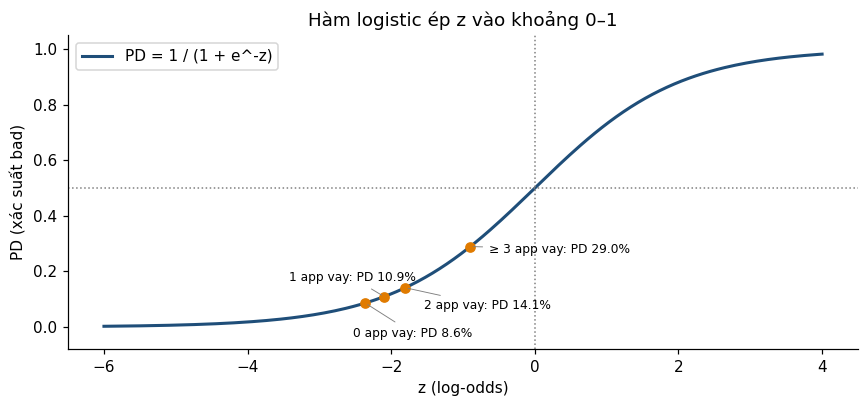

In [18]:
# Hàm logistic đổi z thành PD, đánh dấu 4 nhóm số app vay
zz = np.linspace(-6, 4, 200)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(zz, 1 / (1 + np.exp(-zz)), color="#1F4E79", lw=2, label="PD = 1 / (1 + e^-z)")
names = ["0 app vay", "1 app vay", "2 app vay", "≥ 3 app vay"]
offsets = [(-8, -22), (-62, 10), (12, -14), (12, -4)]              # đặt nhãn so le cho khỏi chồng nhau
for (b, row), name, off in zip(t.iterrows(), names, offsets):
    z_, p_ = row["z = α + β × WOE"], row["PD = 1/(1+e^-z)"]
    ax.scatter(z_, p_, color="#E07B00", zorder=3)
    ax.annotate(f"{name}: PD {p_:.1%}", (z_, p_),
                textcoords="offset points", xytext=off, fontsize=8,
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.6))
ax.axhline(0.5, color="grey", ls=":", lw=1); ax.axvline(0, color="grey", ls=":", lw=1)
ax.set_xlabel("z (log-odds)"); ax.set_ylabel("PD (xác suất bad)"); ax.set_ylim(-0.08, 1.05)
ax.set_title("Hàm logistic ép z vào khoảng 0–1")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

#### Mô hình đầy đủ: 11 biến

**Giống mô hình 1 biến:** mỗi biến $j$ có một $\beta_j$ riêng, cộng tất cả lại thành $z$:

$$z = \alpha + \beta_{\text{số app vay}} \times \text{WOE}_{\text{số app vay}} + \beta_{\text{tổng số app}} \times \text{WOE}_{\text{tổng số app}} + \dots + \beta_{11} \times \text{WOE}_{11} = \alpha + \sum_{j=1}^{11} \beta_j \times \text{WOE}_j$$

$$PD = \frac{1}{1 + e^{-z}}$$

Mỗi $\beta_j$ bây giờ là **ảnh hưởng của biến $j$ khi đã tính đến các biến còn lại**.

**Training:** đưa 13 biến đã qua quy tắc 1 và 2 vào mô hình. Biến nào ra $\beta_j > 0$ (ngược dấu) thì loại, rồi chạy lại, cho đến khi mọi $\beta_j < 0$ (quy tắc 3, giải thích ở cuối mục này):

In [19]:
cols = list(selected)
while True:
    lr = LogisticRegression(C=1.0, max_iter=2000).fit(x_woe["Train"][cols], train["flag_bad"])
    coef = pd.Series(lr.coef_[0], index=cols)
    if (coef <= 0).all():
        break
    worst = coef.idxmax()
    print("Loại vì hệ số ngược dấu:", worst)
    iv_log.loc[worst, "Quyết định"] = "Loại: hệ số ngược dấu"
    cols.remove(worst)

lr_cols = cols
print("\nBiến cuối cùng ({}):".format(len(lr_cols)))
coef.round(3).sort_values()

Loại vì hệ số ngược dấu: call_dur_total_log
Loại vì hệ số ngược dấu: call_pct_out_night

Biến cuối cùng (11):


n_apps                 -1.439
n_loan_apps            -1.312
employment_duration    -1.051
employment_type        -0.951
call_total             -0.842
n_bank_apps            -0.795
fb_age_gap             -0.780
fb_days_since_update   -0.749
call_pct_other         -0.488
call_pct_in_day        -0.474
education              -0.468
dtype: float64

#### Vì sao 2 biến bị loại?

Ô trên in ra 2 biến bị loại vì hệ số ngược dấu: `call_dur_total_log` (tổng thời lượng gọi) và `call_pct_out_night` (% cuộc gọi đi ban đêm). Khi đứng một mình, cả hai đều có hệ số âm (đúng chiều), nhưng khi vào mô hình chung với các biến khác thì hệ số chuyển sang dương:

In [20]:
# Quy tắc 3: vì sao hệ số bị ngược dấu? So sánh hệ số khi biến đứng một mình và khi nằm trong mô hình
rows = []
for c in iv_log.index[iv_log["Quyết định"] == "Loại: hệ số ngược dấu"]:
    solo = LogisticRegression(max_iter=2000).fit(x_woe["Train"][[c]], train["flag_bad"]).coef_[0][0]
    full = LogisticRegression(C=1.0, max_iter=2000).fit(x_woe["Train"][lr_cols + [c]], train["flag_bad"])
    top = x_woe["Train"][lr_cols].corrwith(x_woe["Train"][c]).abs().sort_values(ascending=False).head(2)
    rows.append({"Biến": c, "Hệ số khi đứng một mình": round(solo, 3),
                 "Hệ số trong mô hình": round(pd.Series(full.coef_[0], index=lr_cols + [c])[c], 3),
                 "Tương quan cao nhất với biến đã giữ": ", ".join(f"{k} ({v:.2f})" for k, v in top.items())})
pd.DataFrame(rows)

,Biến,Hệ số khi đứng một mình,Hệ số trong mô hình,Tương quan cao nhất với biến đã giữ
0,call_dur_total_log,-0.988,0.555,"call_pct_other (0.56), call_pct_in_day (0.54)"
1,call_pct_out_night,-0.987,0.017,"call_pct_in_day (0.49), call_pct_other (0.35)"


Hai biến này trùng thông tin với các biến cuộc gọi đã giữ, như tổng số cuộc gọi và % cuộc gọi đến ban ngày. Khi vào mô hình chung, hệ số chỉ đo phần thông tin riêng của biến; phần riêng còn lại của 2 biến này chủ yếu là nhiễu, nên hệ số bị đổi dấu. Giữ lại thì scorecard sẽ trừ điểm người gọi điện nhiều, trái với dữ liệu, nên 2 biến bị loại. Mô hình còn **11 biến**:

**Hệ số của mô hình cuối cùng (11 biến):**

In [21]:
alpha = lr.intercept_[0]
betas = pd.Series(lr.coef_[0], index=lr_cols)
print(f"z = {alpha:.3f}")
for c, b in betas.items():
    print(f"    + ({b:.3f}) × WOE_{c}")

z = -1.925
    + (-1.312) × WOE_n_loan_apps
    + (-0.795) × WOE_n_bank_apps
    + (-1.439) × WOE_n_apps
    + (-0.468) × WOE_education
    + (-0.474) × WOE_call_pct_in_day
    + (-0.488) × WOE_call_pct_other
    + (-0.842) × WOE_call_total
    + (-0.780) × WOE_fb_age_gap
    + (-1.051) × WOE_employment_duration
    + (-0.951) × WOE_employment_type
    + (-0.749) × WOE_fb_days_since_update


**Dự báo cho khách đầu tiên trong bảng ở mục 4.2**: lấy WOE của khách ở từng biến, nhân với β của biến đó, rồi cộng lại.

In [22]:
k = sample.index[0]
steps = pd.DataFrame({
    "Giá trị gốc": [train.loc[k, c] for c in lr_cols],
    "Nhóm": [to_bins(train.loc[[k], c], specs[c]).iloc[0] for c in lr_cols],
    "WOE": x_woe["Train"].loc[k, lr_cols].values,
    "β (hệ số)": betas.values,
}, index=lr_cols)
steps["β × WOE"] = steps["β (hệ số)"] * steps["WOE"]

z_k = alpha + steps["β × WOE"].sum()
pd_k = 1 / (1 + np.exp(-z_k))
print(f"Tổng β × WOE      = {steps['β × WOE'].sum():.3f}")
print(f"z = α + tổng      = {alpha:.3f} + ({steps['β × WOE'].sum():.3f}) = {z_k:.3f}")
print(f"PD = 1/(1+e^-z)   = {pd_k:.2%}")
print(f"Máy tính (predict_proba) = {lr.predict_proba(x_woe['Train'].loc[[k], lr_cols])[0, 1]:.2%}   ← khớp")
print(f"Thực tế khách này: flag_bad = {train.loc[k, 'flag_bad']}")
steps.round(3)

Tổng β × WOE      = -0.287
z = α + tổng      = -1.925 + (-0.287) = -2.212
PD = 1/(1+e^-z)   = 9.87%
Máy tính (predict_proba) = 9.87%   ← khớp
Thực tế khách này: flag_bad = 0


,Giá trị gốc,Nhóm,WOE,β (hệ số),β × WOE
n_loan_apps,0,"(-inf, 0.0]",0.450,-1.312,-0.591
n_bank_apps,0,"(-inf, 0.0]",-0.246,-0.795,0.196
n_apps,12,"(-inf, 19.0]",-0.419,-1.439,0.602
education,4,"(3.0, inf]",0.393,-0.468,-0.184
call_pct_in_day,35.04,"(32.123, inf]",0.239,-0.474,-0.113
call_pct_other,27.68,"(20.0, 28.38]",0.104,-0.488,-0.051
call_total,448.0,"(185.0, inf]",-0.299,-0.842,0.251
fb_age_gap,NaN,Missing,0.198,-0.780,-0.154
employment_duration,51,"(36.0, inf]",0.199,-1.051,-0.209
employment_type,Full-time,Full-time,0.112,-0.951,-0.106


**Đổi thành bảng điểm (scorecard).** Thang điểm thông dụng: **600 điểm ↔ tỷ lệ good:bad = 10:1** (PD khoảng 9%), cứ **thêm 50 điểm** thì tỷ lệ đó gấp đôi (rủi ro giảm một nửa). Đây là cách quy đổi phổ biến khi xây scorecard ("points to double the odds").

**Từ PD sang điểm.** Gọi odds = tỷ lệ good : bad $= \frac{1 - PD}{PD}$:

$$\text{Điểm} = 600 + \frac{50}{\ln 2} \times \left(\ln \frac{1 - PD}{PD} - \ln 10\right)$$

Vì $\ln \frac{1 - PD}{PD} = -z$, công thức này chính là $\text{Điểm} = 433{,}9 - 72{,}1 \times z$: **z càng thấp (an toàn) thì điểm càng cao**.

**Điểm của từng nhóm.** Chia đều $\alpha$ cho $k = 11$ biến, nhóm $i$ của biến $j$ được:

$$\text{Điểm}_{j,i} = \frac{433{,}9}{11} - 72{,}1 \times \left(\beta_j \times \text{WOE}_{j,i} + \frac{\alpha}{11}\right)$$

Cộng điểm của 11 biến lại ra đúng tổng điểm ở trên.

In [23]:
BASE_SCORE, BASE_ODDS, PDO = 600, 10, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

rows = []
for c, beta in zip(lr_cols, lr.coef_[0]):
    for b, w in specs[c]["table"]["woe"].items():
        pts = offset / len(lr_cols) - factor * (beta * w + lr.intercept_[0] / len(lr_cols))
        rows.append({"Biến": c, "Nhóm": b, "WOE": round(w, 2), "Điểm": round(pts)})
scorecard = pd.DataFrame(rows)
scorecard[scorecard["Biến"] == "n_loan_apps"]

,Biến,Nhóm,WOE,Điểm
0,n_loan_apps,"(-inf, 0.0]",0.45,95
1,n_loan_apps,"(0.0, 1.0]",0.19,70
2,n_loan_apps,"(1.0, 2.0]",-0.11,42
3,n_loan_apps,"(2.0, inf]",-1.01,-44


### 5.2 Gradient Boosting

Dùng toàn bộ biến (không cần WOE, mô hình tự chia nhóm). Để tránh overfitting, cây được xây dựng với 7 lá, mỗi lá ít nhất 500 hồ sơ, và dừng sớm khi điểm trên một phần dữ liệu để riêng không tăng nữa (early stopping) [5, chương 10].

**Ý tưởng:** cây thứ nhất dự đoán thô → cây thứ hai sửa phần sai của cây thứ nhất → … cứ thế hàng trăm cây. Cộng điểm của tất cả các cây lại, rồi đổi thành PD bằng **đúng hàm logistic** như Logistic Regression:

$$PD = \frac{1}{1 + e^{-(\text{tổng điểm của các cây})}}$$

In [24]:
ALL_COLS = NUMERIC + CATEGORICAL
categories = {c: sorted(train[c].astype(str).unique()) for c in CATEGORICAL}

def encode(frame):
    out = frame[ALL_COLS].copy()
    for c in CATEGORICAL:
        out[c] = pd.Categorical(out[c].astype(str), categories=categories[c]).codes
    return out

gb = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=1000, max_leaf_nodes=7, min_samples_leaf=500, l2_regularization=1.0,
    categorical_features=[ALL_COLS.index(c) for c in CATEGORICAL],
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
gb.fit(encode(train), train["flag_bad"])
print("Số cây đã dùng:", gb.n_iter_)

Số cây đã dùng: 430


## 6. Đánh giá và chọn mô hình

### 6.1 Mô hình nào phân biệt good / bad tốt hơn? (AUC)

- **AUC**: xác suất một khách bad bị chấm rủi ro hơn một khách good (0,5 = đoán bừa, 1 = hoàn hảo) [8]. Basel trình bày Accuracy Ratio và ROC là công cụ đo khả năng phân biệt của mô hình PD [3, tr. 36–39].
- **AR** (Accuracy Ratio, giống Bài I) = 2 × AUC − 1. Cùng ý nghĩa với AUC, chỉ đổi thang: 0 = đoán bừa, 1 = hoàn hảo.

$$\text{AR} = 2 \times \text{AUC} - 1$$

In [25]:
preds = {
    "Logistic (scorecard)": {k: lr.predict_proba(x_woe[k][lr_cols])[:, 1] for k in sets},
    "Gradient Boosting": {k: gb.predict_proba(encode(v))[:, 1] for k, v in sets.items()},
}
auc = pd.DataFrame({m: {k: roc_auc_score(sets[k]["flag_bad"], p) for k, p in by_set.items()}
                    for m, by_set in preds.items()}).T
auc.columns = ["Train", "Validation", "Test (tháng 6–7)"]
auc["AR trên test"] = 2 * auc["Test (tháng 6–7)"] - 1
auc.round(3)

,Train,Validation,Test (tháng 6–7),AR trên test
Logistic (scorecard),0.734,0.743,0.729,0.458
Gradient Boosting,0.826,0.784,0.773,0.547


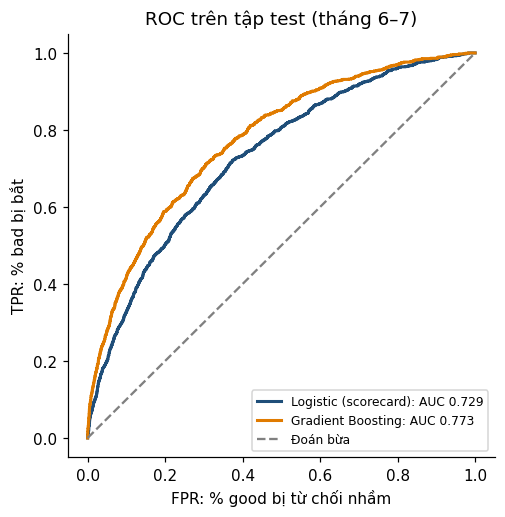

In [26]:
fig, ax = plt.subplots(figsize=(5, 5))
y_test = test["flag_bad"]
for (m, by_set), color in zip(preds.items(), ["#1F4E79", "#E07B00"]):
    fpr, tpr, _ = roc_curve(y_test, by_set["Test OOT"])
    ax.plot(fpr, tpr, color=color, lw=2, label="{}: AUC {:.3f}".format(m, roc_auc_score(y_test, by_set["Test OOT"])))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Đoán bừa")
ax.set_xlabel("FPR: % good bị từ chối nhầm"); ax.set_ylabel("TPR: % bad bị bắt")
ax.set_title("ROC trên tập test (tháng 6–7)"); ax.legend(loc="lower right", fontsize=8)
plt.show()

**Nhận xét:**
- Trên tập test, **Boosting tốt hơn Logistic** khoảng 0,044 AUC (AR 0,55 so với 0,46).
- Logistic gần như không chênh giữa train và test: ổn định nhưng không quá giỏi.
- Boosting cao hơn hẳn trên train so với test, nghĩa là có **overfitting một phần**, nhưng điểm trên test set (điểm quan trọng nhất) vẫn cao hơn Logistic.

### 6.2 Con số PD dự báo có khớp thực tế không?

Mô hình đưa ra con số PD (ví dụ "khách này 9% khả năng bad") và ngân hàng dùng con số này để định giá khoản vay và trích lập dự phòng, nên cần kiểm tra nó có đúng không.

- Liên hệ với Bài I: Bài I kiểm định theo Master Scale có sẵn (10 hạng cố định do ngân hàng đặt). Mô hình ở bài này chưa có thang hạng, nên khách được chia thành 10 nhóm bằng nhau theo PD dự báo, cách chuẩn khi kiểm tra một mô hình mới.


- Chia khách trong test set thành 10 nhóm theo PD dự báo (nhóm 1 = rủi ro nhất), rồi so PD dự báo (đường cam) với tỷ lệ bad thực tế (cột xanh) của mỗi nhóm. Hai cột càng sát nhau thì PD càng đúng.

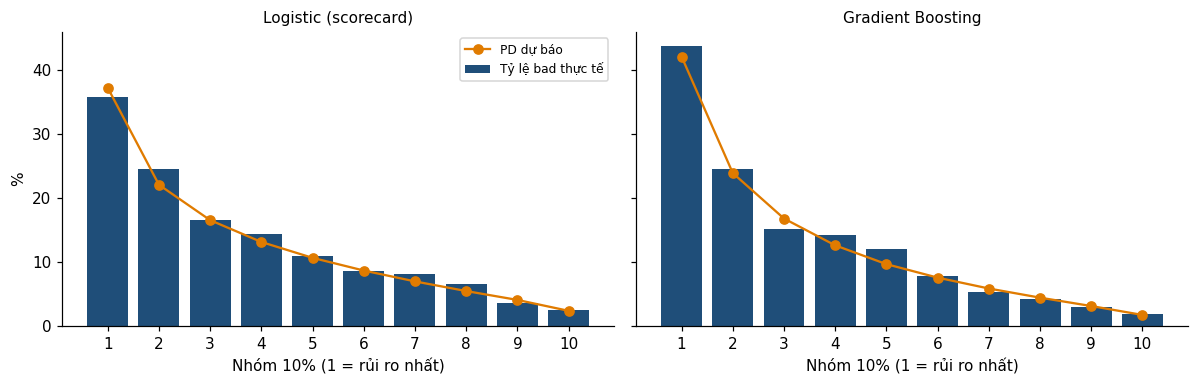

In [27]:
def decile_table(y, p):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    t["nhóm"] = pd.qcut(t["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    g = t.groupby("nhóm", observed=True).agg(n=("y", "size"), bad=("y", "sum"), pd_tb=("p", "mean"))
    g["tỷ lệ bad"] = g["bad"] / g["n"]
    return g

def hosmer_lemeshow(g):
    e = g["n"] * g["pd_tb"]
    hl = float(((g["bad"] - e) ** 2 / (e * (1 - g["pd_tb"]))).sum())
    return hl, float(stats.chi2.sf(hl, len(g)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (m, by_set) in zip(axes, preds.items()):
    g = decile_table(y_test, by_set["Test OOT"])
    hl, p = hosmer_lemeshow(g)
    ax.bar(g.index.astype(int), g["tỷ lệ bad"] * 100, color="#1F4E79", label="Tỷ lệ bad thực tế")
    ax.plot(g.index.astype(int), g["pd_tb"] * 100, "o-", color="#E07B00", label="PD dự báo")
    ax.set_title(m, fontsize=10)
    ax.set_xlabel("Nhóm 10% (1 = rủi ro nhất)"); ax.set_xticks(range(1, 11))
axes[0].set_ylabel("%"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

- Ở cả hai mô hình, cột xanh (thực tế) và đường cam (dự báo) **gần nhau ở mọi nhóm**, chấm cam lúc cao hơn, lúc thấp hơn cột xanh một chút (khoảng 1–2 điểm %), không lệch hẳn về một phía. Tính chung, PD dự báo trung bình khoảng 12,8% so với tỷ lệ bad thực tế 13,2%, tức thấp hơn khoảng 0,4 điểm % (khoảng 3%). Mức lệch này nhỏ hơn nhiều so với mô hình ở Bài I (PD thấp hơn thực tế khoảng 31%). Kiểm định Hosmer-Lemeshow (Bài I) cũng đạt với cả hai mô hình.
- Thứ tự đúng: tỷ lệ bad giảm đều từ nhóm 1 (rủi ro nhất) đến nhóm 10 (an toàn nhất).
- Gradient Boosting nhận ra khách xấu tốt hơn: 10% khách rủi ro nhất do Gradient Boosting chọn có tỷ lệ bad khoảng 44%, so với 36% của Logistic.


### 6.3 Mô hình dựa vào biến nào?

Hai biểu đồ cho biết mỗi mô hình dựa nhiều nhất vào biến nào. Mỗi mô hình đo theo cách riêng: Logistic dùng độ lớn hệ số $|\beta|$, còn Gradient Boosting đo AUC giảm bao nhiêu khi biến đó bị làm mất thông tin.

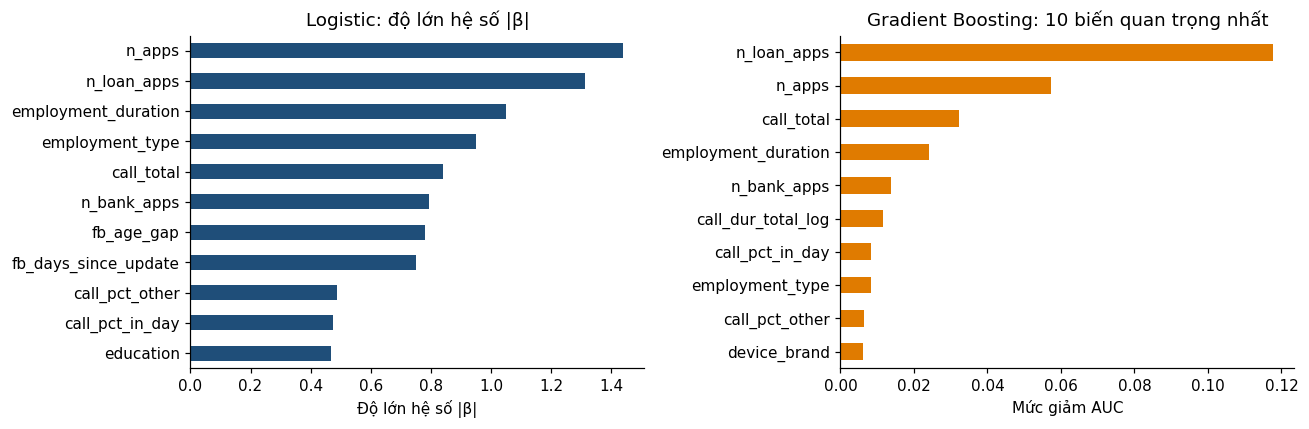

In [28]:
imp = permutation_importance(gb, encode(valid), valid["flag_bad"], scoring="roc_auc", n_repeats=5, random_state=SEED)
gb_imp = pd.Series(imp.importances_mean, index=ALL_COLS).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.abs().sort_values().plot.barh(ax=axes[0], color="#1F4E79", title="Logistic: độ lớn hệ số |β|")
axes[0].set_xlabel("Độ lớn hệ số |β|")
gb_imp.sort_values().plot.barh(ax=axes[1], color="#E07B00", title="Gradient Boosting: 10 biến quan trọng nhất")
axes[1].set_xlabel("Mức giảm AUC")
plt.tight_layout(); plt.show()

Hai mô hình đồng ý về các biến quan trọng nhất: *số app vay (n_loan_apps), tổng số app (n_apps), hoạt động gọi điện (call_total), thâm niên làm việc (employment_duration)*.

### 6.4 Kiểm tra thêm: chia theo thời gian hay chia ngẫu nhiên đều các tháng?

Ở mục 3, bài chọn chia training and test set theo thời gian. Phần này kiểm tra nếu chia training và test set theo cách thông thường (ngẫu nhiên) thì kết quả có khác không, và mỗi cách cho biết điều gì.

So sánh hai cách tạo test set, với cùng số hồ sơ test và cùng toàn bộ quy trình (chia nhóm WOE, chọn biến, 2 mô hình):

| | Training + Validation | Test set |
|---|---|---|
| **Cách A – theo thời gian** (cách đang dùng) | Tháng 1–5 | Tháng 6–7 |
| **Cách B – ngẫu nhiên đều các tháng** | Lấy ngẫu nhiên từ cả 7 tháng | Lấy ngẫu nhiên từ cả 7 tháng, giữ đúng tỷ lệ từng tháng và tỷ lệ bad |

In [29]:
def run_pipeline(train, test):
    """Chạy lại toàn bộ bước 4-5 trên một cách chia dữ liệu, trả về AUC trên test set."""
    sp = {c: fit_binning(train[c], train["flag_bad"], "numeric") for c in NUMERIC}
    sp.update({c: fit_binning(train[c], train["flag_bad"], "categorical") for c in CATEGORICAL})
    xw_train = woe_transform(train, sp, NUMERIC + CATEGORICAL)
    xw_test = woe_transform(test, sp, NUMERIC + CATEGORICAL)

    # Chọn biến: IV >= 0,02 và không tương quan cao với biến đã chọn
    iv_ = pd.Series({c: s["iv"] for c, s in sp.items()}).sort_values(ascending=False)
    corr_ = xw_train.corr().abs()
    cols_ = []
    for c in iv_.index:
        if iv_[c] >= 0.02 and not any(corr_.loc[c, k] > 0.6 for k in cols_):
            cols_.append(c)
    # Logistic: loại dần biến có hệ số ngược dấu
    while True:
        m_lr = LogisticRegression(C=1.0, max_iter=2000).fit(xw_train[cols_], train["flag_bad"])
        coef_ = pd.Series(m_lr.coef_[0], index=cols_)
        if (coef_ <= 0).all():
            break
        cols_.remove(coef_.idxmax())

    cats_ = {c: sorted(train[c].astype(str).unique()) for c in CATEGORICAL}
    def enc(frame):
        out = frame[ALL_COLS].copy()
        for c in CATEGORICAL:
            out[c] = pd.Categorical(out[c].astype(str), categories=cats_[c]).codes
        return out
    m_gb = HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=1000, max_leaf_nodes=7, min_samples_leaf=500, l2_regularization=1.0,
        categorical_features=[ALL_COLS.index(c) for c in CATEGORICAL],
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
    m_gb.fit(enc(train), train["flag_bad"])

    y = test["flag_bad"]
    auc_lr = roc_auc_score(y, m_lr.predict_proba(xw_test[cols_])[:, 1])
    auc_gb = roc_auc_score(y, m_gb.predict_proba(enc(test))[:, 1])
    return {"Logistic (scorecard)": auc_lr, "Gradient Boosting": auc_gb}

# Cách A: theo thời gian (train / test giống mục 3)
auc_time = run_pipeline(train, test)

# Cách B: ngẫu nhiên đều các tháng, test set cùng kích thước với cách A.
# Chia ngẫu nhiên 5 lần (5 seed khác nhau) để xem kết quả dao động bao nhiêu.
strata = df["month"] + "_" + df["flag_bad"].astype(str)        # giữ tỷ lệ từng tháng và tỷ lệ bad
random_runs = []
for seed in range(5):
    dev_r, test_r = train_test_split(df, test_size=len(test), stratify=strata, random_state=seed)
    train_r, _ = train_test_split(dev_r, test_size=0.25, stratify=dev_r["flag_bad"], random_state=seed)
    random_runs.append(run_pipeline(train_r, test_r))
random_runs = pd.DataFrame(random_runs)

compare = pd.DataFrame({
    "A – theo thời gian": pd.Series(auc_time),
    "B – ngẫu nhiên (trung bình 5 lần)": random_runs.mean(),
    "B – thấp nhất": random_runs.min(),
    "B – cao nhất": random_runs.max(),
}).T
compare.index.name = "AUC trên test set"
compare.round(3)

,Logistic (scorecard),Gradient Boosting
AUC trên test set,,
A – theo thời gian,0.729,0.773
B – ngẫu nhiên (trung bình 5 lần),0.732,0.771
B – thấp nhất,0.724,0.764
B – cao nhất,0.736,0.781


**Kết quả:** sau khi chia ngẫu nhiên 5 lần, AUC dao động khoảng **0,72–0,74** (Logistic) và **0,76–0,78** (Gradient Boosting). Kết quả của cách chia theo thời gian (0,729 và 0,773) nằm trong khoảng đó. Điều này cho thấy hai cách cho kết quả tương đương.

In [30]:
# Training set và test set của mỗi cách gồm hồ sơ tháng nào?
months_dist = pd.DataFrame({
    "A – training": train["month"].value_counts(normalize=True),
    "A – test": test["month"].value_counts(normalize=True),
    "B – training": train_r["month"].value_counts(normalize=True),
    "B – test": test_r["month"].value_counts(normalize=True),
}).fillna(0).sort_index()
(months_dist * 100).round(0).astype(int).astype(str) + "%"


,A – training,A – test,B – training,B – test
month,,,,
2018-01,14%,0%,11%,11%
2018-02,18%,0%,13%,14%
2018-03,20%,0%,15%,15%
2018-04,22%,0%,17%,17%
2018-05,27%,0%,21%,21%
2018-06,0%,68%,15%,15%
2018-07,0%,32%,7%,7%


**Hai cách khác nhau ở đâu?**
- **Cách A:** training chỉ có tháng 1–5, test chỉ có tháng 6–7. Mô hình được kiểm tra trên khách tương lai mà nó chưa từng thấy, giống lúc ngân hàng dùng thật.
- **Cách B:** training và test có tỷ lệ các tháng gần như giống nhau. Mô hình đã được học một phần khách tháng 6–7, nên test set có cùng kiểu khách với lúc học.

**Khách tháng 6–7 có khác thật không? Ví dụ: dữ liệu Facebook**

In [31]:
fb_by_month = pd.crosstab(df["month"], df["has_fb"], normalize="index").rename(
    columns={"Yes": "Có Facebook", "No": "Không có Facebook"})
(fb_by_month * 100).round(0).astype(int).astype(str) + "%"

has_fb,Không có Facebook,Có Facebook
month,,
2018-01,0%,100%
2018-02,0%,100%
2018-03,0%,100%
2018-04,0%,100%
2018-05,0%,100%
2018-06,5%,95%
2018-07,39%,61%


- Tháng 1–5: 100% hồ sơ có dữ liệu Facebook. Tháng 6 còn khoảng 95%, tháng 7 chỉ còn khoảng 61%.
- Nếu chia ngẫu nhiên (cách B), những hồ sơ không có Facebook bị trộn vào cả training lẫn test, nên *không thấy được thay đổi này*. Chia theo thời gian (cách A) giúp phát hiện nó và kiểm tra mô hình có chịu được hay không. Ở bài này mô hình vẫn chịu được: AUC trên test set vẫn đạt 0,73 / 0,77.
- Nếu đưa mô hình vào dùng, cần theo dõi tỷ lệ thiếu dữ liệu Facebook, vì scorecard có dùng 2 biến Facebook.

**Nếu sự thay đổi ảnh hưởng mạnh đến kết quả thì sao?**

Ở bài này, các biến Facebook chỉ là tín hiệu phụ nên AUC vẫn giữ được. Với một bộ dữ liệu khác, thay đổi ở các tháng cuối có thể ảnh hưởng mạnh hơn (ví dụ một biến quan trọng bị thiếu, hoặc khách mới có hành vi khác hẳn). Khi đó mô hình sẽ dự báo kém với khách mới, *dù chia theo cách nào*.

| | Chia ngẫu nhiên | Chia theo thời gian |
|---|---|---|
| Mô hình được học | một phần khách của các tháng cuối | chỉ các tháng trước |
| AUC trên test set | vẫn cao, nên tưởng mô hình tốt | giảm, nên phát hiện có vấn đề |
| Khi dùng thật cho khách mới | AUC giảm, ngân hàng chỉ biết sau khi đã cho vay | đã biết trước, sửa trước khi dùng |

Vì vậy, chia theo thời gian không làm mô hình tốt hơn, mà giúp *không bị bất ngờ* khi dùng thật.

Đây là lý do bài giữ **cách A** làm kết quả chính.

## Kết luận

| | Logistic (scorecard) | Gradient Boosting |
|---|---|---|
| AUC trên test (tháng 6–7) | 0,729 | **0,773** |
| AR trên test | 0,46 | **0,55** |
| PD dự báo khớp thực tế (6.2) | Đạt | Đạt |
| Giữ được AUC trên tháng 6–7 (6.4) | Đạt | Đạt |
| Dễ giải thích | **Dễ** | Khó hơn |

**Đề xuất:** dùng **Gradient Boosting** làm mô hình chính vì dự báo tốt hơn rõ rệt trên dữ liệu tương lai, AUC vẫn giữ được trên tháng 6–7 và PD dự báo khớp thực tế. Giữ **Logistic scorecard** làm mô hình đối chứng, và là phương án thay thế khi cần giải thích từng điểm số (ví dụ lý do từ chối).

**Tín hiệu mạnh nhất:** số app vay trong máy. Các demographic features như tuổi, lương, giới tính gần như không có sức dự báo trong dữ liệu này.

### Hạn chế và bước tiếp theo
- **Phạm vi của bài:** bài tập trung vào cách áp dụng mô hình và đọc kết quả. Một số phần được trình bày ở mức đơn giản và có thể đi sâu hơn: cơ chế toán học bên trong Gradient Boosting, kiểm định Hosmer-Lemeshow chi tiết (đã làm ở Bài I), theo dõi độ ổn định bằng PSI, và các cách đo mức quan trọng của biến.
- Cách đếm app vay còn thô (dựa trên từ khóa trong tên app).
- Chưa dò tham số có hệ thống cho Boosting (ví dụ cross-validation theo thời gian).
- Chưa giải thích được từng khách hàng (cần SHAP [11]).
- Chưa biết "bad" được định nghĩa là quá hạn bao nhiêu ngày; ngưỡng duyệt cần chọn cùng nghiệp vụ.
- Dữ liệu chỉ có người đã được duyệt vay, nên mô hình chưa thấy người bị từ chối (reject inference [2, tr. 187]).
- Chưa kiểm tra tính công bằng giữa các nhóm (ví dụ giới tính).
- Tháng 7 có khoảng 39% hồ sơ không có dữ liệu Facebook (mục 6.4). Cần theo dõi vì scorecard dùng 2 biến Facebook.
- Scorecard chấm PD cho khách không có Facebook cao hơn thực tế (PD dự báo trung bình 13,5%, tỷ lệ bad thực tế 10,0% trên test set). Nguyên nhân: nhóm "Missing" của `fb_days_since_update` chỉ có **2 hồ sơ** trong training set (tháng 1–5 ai cũng có Facebook), nên WOE của nhóm này không đáng tin, trong khi tháng 7 có 39% hồ sơ rơi vào nhóm này. Gradient Boosting không bị lỗi này (PD dự báo 10,3%). Đề xuất cách sửa: nhóm nào quá ít hồ sơ (ví dụ < 100) thì gán WOE = 0 (trung tính), hoặc hiệu chỉnh lại PD cho nhóm này.
- Hồ sơ tháng 7 mới nhất nên có thể chưa đủ thời gian để lộ ra là bad. Tỷ lệ bad tháng 7 thấp hơn tháng 6 có thể một phần vì lý do này.
- Mô hình hiện chỉ học dữ liệu tháng 1–5 (tháng 6–7 được giữ riêng để kiểm tra). Trước khi dùng thật, nên huấn luyện lại theo đúng quy trình này trên cả 7 tháng, để mô hình học được thay đổi gần nhất (ví dụ dữ liệu Facebook).


## Tài liệu tham khảo

Chỉ giữ các nguồn đã kiểm chứng được nội dung (toàn văn, abstract, hoặc nguồn thứ cấp).

**Credit scoring (WOE, IV, scorecard)**

1. Siddiqi, N. (2006). *Credit Risk Scorecards: Developing and Implementing Intelligent Credit Scoring*. Wiley. (Bản 2: *Intelligent Credit Scoring*, 2017.)
2. Delamaire, L. (2012). *Implementing a credit risk management system based on innovative scoring techniques* (Doctoral thesis). University of Birmingham. http://etheses.bham.ac.uk/3344/ (tr. 152: cách đọc IV và dấu của biến; tr. 187: reject inference)

**Kiểm định mô hình PD**

3. Basel Committee on Banking Supervision (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements.

**Logistic Regression và Gradient Boosting**

4. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. Bản PDF miễn phí: https://www.statlearning.com
5. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
6. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
7. Ke, G., Meng, Q., Finley, T., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30*.

**Đánh giá, rò rỉ dữ liệu, giải thích mô hình**

8. Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29–36.
9. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21.
10. Lessmann, S., Baesens, B., Seow, H.-V., & Thomas, L. C. (2015). Benchmarking state-of-the-art classification algorithms for credit scoring: An update of research. *European Journal of Operational Research, 247*(1), 124–136.
11. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30*.